# 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.base import clone

# 1. Kontext und Zielsetzung

## Der Kunde

Das Formel-1-Team „Vantage Racing“ hat sich in der Saison 2027 das Ziel gesetzt, aus dem Mittelfeld der Drivers’ Championship in die Top 3 zu gelangen. Die Regularien der Formel 1 geben den Teams viel Spielraum bei der Entwicklung ihrer Fahrzeuge. Um datengestützte Entscheidungen zur Rennstrategie treffen zu können, ist es daher unerlässlich, die Datenanalysten der Teams mit Tools auszustatten, welche das Team bei diesen Entscheidungen unterstützen.

Damit das Team von Vantage Racing das gesetzte Ziel erreichen kann, wird angestrebt, ein Prognose-Tool zu entwerfen, welches mittels Machine Learning während eines Rennens anhand der gegebenen Daten über Wetter, Reifen, Runden und vieles mehr Vorhersagen für den weiteren Stint-Verlauf im Vergleich zur frischen Stint-Pace treffen kann. Hierbei wird die Prognose anhand der Reifenabnutzung getroffen.

Für dieses Prognose-Tool werden die Rundenzeiten aller Rennrunden der vergangenen Saisons 2023 bis 2025 und aller Fahrer eingeschlossen. Da sich jedoch, wie bereits erwähnt, die Fahrzeuge in ihrer Leistung unterscheiden können, müssen variable Einflussfaktoren für die Prognose herausgerechnet werden. Weitere Einflussfaktoren sind die individuelle Leistung des Fahrers, das Setup des Fahrzeugs und die Strecke.

Durch eine Betrachtung des Deltas zwischen dem Median der ersten drei Stintrunden und der aktuellen Runde innerhalb dieses Stints kürzen sich diese Einflussfaktoren weitgehend selbstständig heraus. Mit diesen prognostizierten Delta-Zeiten lässt sich vom Renningenieur feststellen, ab wann ein Reifen so stark abgebaut hat, dass ein Boxenstopp auf frische Reifen eine schnellere Rundenzeit mit sich bringen kann.

Hiermit verspricht sich das Team eine verbesserte Teamstrategie, gewonnene Positionen und letztendlich mehr WM-Punkte.

<div style="background-color: #d1dff1; border-left:6px solid #0c4360; padding:10px; border-radius:4px;">
<b>Anmerkung:</b> Ein <b>Stint</b> bezeichnet in der Formel 1 den Abschnitt eines Rennens, den ein Fahrer mit einem bestimmten Reifensatz zwischen zwei Boxenstopps absolviert. Er beginnt in der Regel nach dem Start oder nach einem Reifenwechsel und endet mit dem nächsten Boxenstopp oder mit dem Ende des Rennens.
</div>

Bei dem Prognose-Tool werden Machine-Learning-Algorithmen genutzt um eine Regression der Delta-Zeiten aus den Trainingsdaten durchzuführen. Zur Bewertung der Qualität der Vorhersage werden die zwei folgenden Qualitätsmetriken herangezogen:

**Mean Absolute Error (MAE):** Der MAE misst die durchschnittliche absolute Abweichung des vorhergesagten Wertes vom tatsächlichen Wert, in unserem Fall der vorhergesagten Delta-Zeit. Er berechnet sich mittels folgender Formel: 
$$MAE=\frac{1}{n} \sum_{i=1}^{n} \vert{}y_i - \hat{y}_i\vert{}$$
Diese Metrik wird gewählt, da die Einheit dieser Metrik direkt und intuitiv für den Renningenieur interpretierbar ist. Gerade für die Abwägung, ob ein Boxenstopp auf frische Reifen eine schnellere Rundenzeit mit sich bringen kann, ist diese Metrik ein wichtiger Faktor.

**Bestimmtheitsmaß ($R^2$):** Das Bestimmtheitsmaß gibt an, welchen Anteil der Streuung in den tatsächlichen Delta-Zeiten das Modell durch seine Vorhersagen erklären kann. Es berechnet sich mittels folgender Formeln:

$$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}}$$

$$SS_{\text{res}} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$SS_{\text{tot}} = \sum_{i=1}^{n} (y_i - \bar{y})^2$$

Hierbei beschreibt $SS_{\text{res}}$ die Summe der quadrierten Abweichungen zwischen den tatsächlichen und den vorhergesagten Delta-Zeiten, während $SS_{\text{tot}}$ die Streuung der tatsächlichen Delta-Zeiten um ihren Mittelwert $\bar{y}$ misst. Ein $R^2$ von 1 bedeutet eine perfekte Vorhersage, ein Wert von 0 entspricht einem Modell, das lediglich den Mittelwert vorhersagt, und negative Werte zeigen, dass ein Modell schlechter abschneidet als das Schätzen des Mittelwertes.

Diese Metrik wird zusätzlich zum MAE gewählt, um abzusichern, dass das Modell nicht lediglich einen konstanten Durchschnittswert vorhersagt, sondern auch die Streuung in den Delta-Zeiten erklärt und damit systematische Muster in der Reifenabnutzung erfasst. 

# 2. Daten

## 2.1 Vorstellung des Datensatzes

Der Datensatz stammt von der [OpenF1 API](https://www.openf1.org "Zur Webseite"), einer öffentlich zugänglichen API mit umfangreichen Daten zur Formel 1. Die Endpunkte dieser API bieten Zugriff auf Telemetrie, Rundenzeiten, Reifenstints, Wetter, Renn-Kontrollnachrichten und vieles mehr — und decken alle Sessions (Rennen, Freie Trainings, Qualifyings) ab der Saison 2023 ab. Die Daten stammen aus den offiziellen Live-Timing-Streams der Formel 1 und sind somit reale Messdaten, keine synthetisch erzeugten Werte.

Die Daten stehen über die OpenF1 API frei und ohne API-Key unter einer Creative-Commons-Lizenz zur Verfügung. Die für dieses Projekt benötigten Daten wurden in der assembly.ipynb einmalig aus der API abgerufen, die Rohantworten der jeweiligen Endpunkte stehen pro Session unter data/raw/ zur Verfügung. Anschließend wurden die Daten der verschiedenen Endpunkte zu einem gemeinsamen Datensatz zusammengeführt und um abgeleitete Spalten ergänzt (u. a. stint_id, stint_age, tyre_age_total sowie die Flags für Boxen- und Streckenzustände). 

Ergänzend wurde jeder Slick-Runde der absolute Reifen-Code (`c_compound`) zugeordnet. Während `compound` nur die relative Reifenmischungswahl (SOFT, MEDIUM, HARD) innerhalb eines Rennwochenendes angibt, benennnt der C-Code die absolute Pirelli-Mischung (C1-C6) und somit mehr Aussagekraft über das Degradationsverhalten. Diese Zuordnung ist über die OpenF1 API nicht verfügbar und wurde aus diesem Grund aus offziellen Pirelli-Pressemitteilungen entnommen, in welchen Pirelli die für den Grand Prix nominierten Reifenmischungen bekanntgibt. Die Extraktion aus den Pressemitteilungen erfolgte untestzützend mit generativer KI. Die Zuordnungen wurden anschließend gegen die Originalquellen geprüft, um die Korrektheit sicherzustellen. Die Pirelli-Pressemitteilungen sind öffentlich einsehbar unter [press.pirelli.com](https://press.pirelli.com).

Eine vollständige Übersicht aller Spalten folgt in Abschnitt 2.3.

## 2.2 Datenumfang

Die für den Datensatz verwendeten Daten stammen aus den vergangenen Formel-1-Saisons 2023 bis 2025. Diese Saisons wurden explizit gewählt, da sich die Regularien der F1-Boliden sowie der Rennen in diesen Jahren wenig bis gar nicht verändert haben (kleine Regeländerungen werden zum Preis des Datenumfangs in Kauf genommen). Dadurch sind diese Saisons vergleichbar und bieten einen großen Umfang an verfügbaren Daten und eine hohe Datenvarianz in Wetter, Strecken und Compounds. Es werden im Datensatz ausschließlich Rennen berücksichtigt, da lediglich Runden aus Rennen repräsentativ für die Runden-Delta-Prognose sind. Außerdem bieten Rennen die konsistentesten Bedingungen im Hinblick auf Renntempo, Reifenmanagement, Stint-Längen und Spritmenge. Über die genannten drei Saisons sind 70 Rennen gefahren worden, das ursprünglich angesetzte Rennen in Imola 2023 wurde wegen Hochwassers abgesagt und ist in OpenF1 entsprechend markiert (is_cancelled), so dass es aus dem Datensatz ausgeschlossen wird. Im Datensatz entspricht eine Zeile einer Rennrunde eines Fahrers, dadurch kommt der Datensatz auf ca. 77.000 Rennrunden der vergangenen drei Saisons.

## 2.3 Spalten des Datensatzes

| Spalte | Quelle | Bedeutung | Rolle |
|---|---|---|---|
| `session_key` | `sessions` | ID der Rennsession | ID |
| `driver_number` | `laps` / `drivers` | Startnummer des Fahrers | ID / Feature  |
| `stint_number` | `stints` | Laufende Nr. des Reifen-Stints im Rennen | ID |
| `stint_id` | abgeleitet | Kombi aus session, driver und stint_number, Gruppenschlüssel für den späteren Train-/Test-Split | ID |
| `track_id` | `sessions` / `meetings` | ID der Rennstrecke | ID |
| `team_id` | `drivers` | Team-/Konstrukteur-Zuordnung | ID |
| `year` | `sessions` | Saisonjahr (2023 – 2025) | Kontext |
| `lap_number` | `laps` | Runden-Nr. innerhalb des Rennens | Kontext |
| `lap_start` | `laps` | Startrunde des Stints | Kontext |
| `lap_end` | `laps` | Endrunde des Stints | Kontext |
| `date_start` | `stints` | Zeitstempel des Stintbeginns (UTC) | Kontext |
| `lap_duration` | `laps` | Gefahrene Rundenzeit in Sekunden | **Target-Quelle** |
| `stint_age` | abgeleitet | Wievielte Runde innerhalb des aktuellen Stints (1 = erste Runde) | Feature |
| `compound` | `stints` | Reifenmischung (soft / medium / hard / intermediate / wet) | Filter |
| `c_compound` | Join (Pirelli-Zuordnung) | Absolute Reifenmischung (C1–C6) | Feature |
| `tyre_age_at_start` | `stints` | Bereits gefahrene Runden auf diesem Reifensatz beim Stintbeginn (>0 bei gebrauchten Reifen) | Feature |
| `tyre_age_total` | abgeleitet | Gesamtes Reifenalter dieser Runde (`tyre_age_at_start` + `stint_age`) | abgeleitet |
| `air_temperature` | `weather` | Lufttemperatur in °C | Feature |
| `track_temperature` | `weather` | Asphalttemperatur in °C | Feature |
| `humidity` | `weather` | Luftfeuchtigkeit in % | Feature |
| `rainfall` | `weather` | Niederschlagsindikator | Filter |
| `is_pit_out_lap` | `laps` | Erste Runde nach Boxenstopp (Out-Lap) | Flag |
| `is_in_lap` | abgeleitet (Stint-Struktur) | Letzte Runde eines Stints (endet im Boxenstopp) | Flag |
| `is_under_sc` | `race_control` | Safety Car aktiv in dieser Runde | Flag |
| `is_under_vsc` | `race_control` | Virtual Safety Car aktiv in dieser Runde | Flag |
| `is_under_yellow` | `race_control` | Gelbe Flagge in dieser Runde geschwenkt| Flag |
| `is_red_flag_lap` | `race_control` | Rote Flagge in dieser Runde geschwenkt | Flag |

<div style="background-color: #d1dff1; border-left:6px solid #0c4360; padding:10px; border-radius:4px;">
<b>Anmerkung:</b> Das eigentliche Modellziel, die Delta-Zeit gegenüber der Referenzrunde des Stints, liegt im Datensatz noch nicht als eigene Spalte vor. Sie wird im Rahmen des Preprocessings (siehe Kapitel 4) aus `lap_duration` und `stint_id` abgeleitet, indem von jeder Rundenzeit innerhalb eines Stints die Rundenzeit der Referenzrunde dieses Stints abgezogen wird.
</div>

# 3. Initiale Datenanalyse

In [2]:
df = pd.read_csv("data/dataset.csv")
df_raw = df.copy()
df.columns

Index(['session_key', 'driver_number', 'lap_number', 'stint_number',
       'stint_id', 'lap_start', 'lap_end', 'date_start', 'lap_duration',
       'compound', 'c_compound', 'tyre_age_at_start', 'stint_age',
       'tyre_age_total', 'track_id', 'team_id', 'year', 'air_temperature',
       'track_temperature', 'humidity', 'rainfall', 'is_pit_out_lap',
       'is_in_lap', 'is_under_sc', 'is_under_vsc', 'is_under_yellow',
       'is_red_flag_lap'],
      dtype='str')

In [3]:
df.shape

(77322, 27)

In [4]:
df.dtypes

session_key            int64
driver_number          int64
lap_number             int64
stint_number         float64
stint_id                 str
lap_start            float64
lap_end              float64
date_start               str
lap_duration         float64
compound                 str
c_compound               str
tyre_age_at_start    float64
stint_age            float64
tyre_age_total       float64
track_id               int64
team_id                  str
year                   int64
air_temperature      float64
track_temperature    float64
humidity             float64
rainfall               int64
is_pit_out_lap          bool
is_in_lap               bool
is_under_sc             bool
is_under_vsc            bool
is_under_yellow         bool
is_red_flag_lap         bool
dtype: object

In [5]:
for column in df.columns:
    print(f"Die Spalte {column} hat {df[column].isna().sum()} NaN-Werte.")

Die Spalte session_key hat 0 NaN-Werte.
Die Spalte driver_number hat 0 NaN-Werte.
Die Spalte lap_number hat 0 NaN-Werte.
Die Spalte stint_number hat 25 NaN-Werte.
Die Spalte stint_id hat 25 NaN-Werte.
Die Spalte lap_start hat 25 NaN-Werte.
Die Spalte lap_end hat 25 NaN-Werte.
Die Spalte date_start hat 0 NaN-Werte.
Die Spalte lap_duration hat 226 NaN-Werte.
Die Spalte compound hat 25 NaN-Werte.
Die Spalte c_compound hat 4409 NaN-Werte.
Die Spalte tyre_age_at_start hat 25 NaN-Werte.
Die Spalte stint_age hat 25 NaN-Werte.
Die Spalte tyre_age_total hat 25 NaN-Werte.
Die Spalte track_id hat 0 NaN-Werte.
Die Spalte team_id hat 0 NaN-Werte.
Die Spalte year hat 0 NaN-Werte.
Die Spalte air_temperature hat 0 NaN-Werte.
Die Spalte track_temperature hat 0 NaN-Werte.
Die Spalte humidity hat 0 NaN-Werte.
Die Spalte rainfall hat 0 NaN-Werte.
Die Spalte is_pit_out_lap hat 0 NaN-Werte.
Die Spalte is_in_lap hat 0 NaN-Werte.
Die Spalte is_under_sc hat 0 NaN-Werte.
Die Spalte is_under_vsc hat 0 NaN-Werte.

Es scheinen einige NaN-Werte im Datensatz vorzukommen, diese sollten im Verlauf der Ausarbeitung behandelt werden.

Zunächst wird die Zeile `rainfall` untersucht, um zu schauen, ob es sich hierbei um ein binäres Feature handelt. Anschließend wird die Werteverteilung der numerischen Features untersucht.

In [6]:
df["rainfall"].value_counts()

rainfall
0    74631
1     2691
Name: count, dtype: int64

In [7]:
NUMERIC = ["lap_duration", "tyre_age_at_start", "stint_age", "tyre_age_total", "air_temperature", "track_temperature", "humidity"]
df[NUMERIC].describe()

,lap_duration,tyre_age_at_start,stint_age,tyre_age_total,air_temperature,track_temperature,humidity
count,77096.000000,77297.000000,77297.000000,77297.000000,77322.000000,77322.000000,77322.000000
mean,94.404093,0.539801,14.238793,14.778594,23.784311,35.115817,53.041153
std,66.635589,1.895614,10.610112,10.733336,4.677317,8.891805,16.191573
min,67.012000,0.000000,1.000000,1.000000,14.200000,16.700000,17.000000
25%,81.442000,0.000000,6.000000,7.000000,19.600000,29.400000,42.000000
50%,89.839000,0.000000,12.000000,13.000000,24.100000,34.100000,55.000000
75%,98.924000,0.000000,20.000000,21.000000,27.300000,42.800000,64.000000
max,2625.541000,54.000000,78.000000,79.000000,33.900000,52.700000,92.000000


Die dargestellte Tabelle der Werteverteilungen bietet eine Grundlage für eine erste Plausibilitätsüberprüfung der Daten. 

`lap_duration`: Die Werte bewegen sich in realistischen Größenordnungen, lediglich der Maximalwert ist deutlich zu hoch. 2625,54 Sekunden entsprechen knapp 44 Minuten, kein realistischer Wert für eine Formel-1-Rennrunde. Vermutlich hat es dort eine rote Flagge (Rennunterbrechung) gegeben und die Rundenzeit wurde weiter gemessen. Im Datensatz liegen Informationen zu den Flaggen während des Rennnens vor, wodurch sich dieser Wert vermutlich später herausfiltern lässt.

`tyre_age_at_start`: Mehr als 75% Reifen wurden vor ihrem Einsatz im Rennen noch nicht verwendet. Das Maximum von 54 gefahrenen Runden des Reifens zu Stint-Beginn ist vermutlich auf falsche / fehlerhafte Team-Strategie zurückzuführen.

`stint_age`: Relistischer Wertebereich, bemerkenswert ist, dass in den Daten ein Rennen mit 79 Runden auf dem gleichen Reifen absolviert wurde.

`air_temperature`, `track_temperature`, `humidity`: Plausible Wertebereiche.

In [8]:
CATEGORIAL = ["compound", "c_compound", "track_id", "team_id", "year", "driver_number"]

for feature in CATEGORIAL:
    print(df[feature].value_counts())

compound
HARD            36275
MEDIUM          28025
SOFT             8613
INTERMEDIATE     4299
WET                85
Name: count, dtype: int64
c_compound
C3    31198
C4    18524
C2    13488
C1     6416
C5     3213
C6       74
Name: count, dtype: int64
track_id
22     4178
55     4133
4      3979
23     3939
19     3887
15     3823
65     3766
14     3500
61     3498
70     3352
63     3316
9      3138
150    3022
39     2953
10     2929
144    2902
46     2852
151    2791
152    2776
2      2762
149    2746
7      2537
6      2445
49     2098
Name: count, dtype: int64
team_id
McLaren            8126
Mercedes           8006
Red Bull Racing    7916
Ferrari            7883
Haas F1 Team       7810
Aston Martin       7644
Alpine             7484
Williams           7124
Kick Sauber        5182
RB                 2609
Racing Bulls       2584
Alfa Romeo         2477
AlphaTauri         2477
Name: count, dtype: int64
year
2024    26615
2025    26246
2023    24461
Name: count, dtype: int64
driv

`compound`: Am häufigsten genutzen Reifen sind `HARD` und `MEDIUM`. Die Regenreifen `WET` und `INTERMEDIATE` werden in dieser Untersuchung nicht betrachtet, die niedrige Anzahl an gefahrenen Runden mit dem `SOFT` Reifen muss später berücksichtigt werden.

`c_compound`: Die im Datensatz am Häufigsten vertretende Reifenmischung ist `C3` gefolgt von `C4` und `C2`. Die Reifenmischung `C6` kommt sehr selten vor, da diese erst zur Mitte der Saison 2025 eingeführt wurde.

`track_id`: Keine Besonderheiten

`team_id`: Die Teams `Alfa Romeo`, `Kick Sauber`, `Racing Bulls`, `RB` und `Alpha Tauri` haben deutlich weniger Rennrunden im Dataset als die restlichen Teams. Dies ist auf Namensänderungen zwischen den Saisons zurückzuführen. Damit die Datengewichtung richtig abgebildet wird, sollten die Teams umbenannt werden.

`driver_number`: Die Werte sind plausibel. Einige Fahrernummern haben lediglich wenige Runden absolviert, da es sich hierbei um Ersatz- und Rookie-Driver handelt.

# 4. Preprocessing & Explorative Datenanalyse

## 4.1 Datenfilterung

Es wurde herausgefunden, dass einige Spalten die selbe Anzahl an NaN values haben. Dies ist auffällig und legt nahe, dass es hierbei um dieselben Zeilen handelt.

In [9]:
nan_counts = df.isna().sum()
nan_counts[nan_counts > 0]

stint_number           25
stint_id               25
lap_start              25
lap_end                25
lap_duration          226
compound               25
c_compound           4409
tyre_age_at_start      25
stint_age              25
tyre_age_total         25
dtype: int64

Die 4409 NaN in `c_compound` entsprechen den Nassreifen-Runden (INTERMEDIATE/WET), für die kein C-Code existiert. Sie werden hier bewusst nicht entfernt, sondern fallen im Verlauf durch die Filterung der Regenreifen weg. Weiterhin fällt auf, dass die `stint_id` NaN values hat. Diese Spalte wurde im assembly.ipynb aus `driver_number`, `session_key` und `stint_number` zusammengebaut. Es werden die Werte der NaN-Stints betrachtet.

In [10]:
nan_stints = df[df["stint_id"].isna()]
nan_stints[["session_key", "driver_number", "lap_number", "lap_start", "lap_end", "lap_duration", "compound", "tyre_age_at_start", "stint_age", "tyre_age_total"]]

,session_key,driver_number,lap_number,lap_start,lap_end,lap_duration,compound,tyre_age_at_start,stint_age,tyre_age_total
2993,7787,16,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12835,9141,81,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15011,9157,22,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15972,9165,22,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17942,9221,44,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21289,9205,23,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21290,9205,20,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21291,9205,16,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
27516,9496,3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
27520,9496,23,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Es fällt auf, dass alle betroffenen NaN-Stints ebenfalls NaN-Werte in den anderen Spalten enthalten. Entsprechend sind diese 25 NaN-Werte der Spalten erkannt. Ebenfalls fällt auf, dass alle NaN-Werte in der ersten Rennrunde vorkommen (`lap_number == 1`). Dies gibt Hinweise auf Zwischenfälle beim Start bzw. in der ersten Rennrunde wodurch kein erster Stint zustande kommen konnte. Nun wird noch die Spalte `lap_duration` untersucht, diese enthält 226 NaN-Werte.

In [11]:
no_lap_duration = df[df["lap_duration"].isna()]
no_lap_duration["lap_number"].value_counts()

lap_number
1     50
52    19
58     7
51     6
57     6
16     6
28     5
53     5
54     5
2      5
6      5
40     4
7      4
59     4
47     4
3      4
63     4
46     4
31     4
42     3
37     3
71     3
72     3
24     3
8      3
23     3
27     3
50     3
34     3
56     3
18     2
10     2
13     2
32     2
68     2
15     2
41     2
67     2
4      2
65     2
39     2
26     2
14     1
17     1
79     1
43     1
62     1
21     1
11     1
48     1
20     1
9      1
33     1
5      1
45     1
49     1
25     1
35     1
38     1
36     1
Name: count, dtype: int64

In [12]:
df.groupby(["session_key", "driver_number"])["lap_number"].transform("max").value_counts().head(10)

lap_number
57    9082
70    7276
71    6602
56    5748
50    4945
69    4554
52    4413
58    3884
53    3657
72    3239
Name: count, dtype: int64

Es fällt auf, dass sich ein großteil der NaN-Werte ebenfalls der ersten Rennrunde zuordnen lassen. Weiterhin kommen viele weitere NaN-Werte eher in den höheren Rennrunden vor. Die Rennen im Datensatz haben meist zwischen 50 und 75 Rennrunden, entsprechend könnte das einen Hinweis darauf geben, dass es sich bei diesen NaN-Werten um die letzte Rennrunde eines Fahrers handeln könnte. Dies gilt es zu untersuchen. Im Folgenden wird geprüft bei wie vielen NaN-Zeilen von `lap_duration` es sich um die letzte Rennrunde handelt.

In [13]:
last_laps = df.groupby(["session_key", "driver_number"])["lap_number"].transform("max") # find highest lap numbers
higher_laps = df[df["lap_duration"].isna() & (df["lap_number"] > 1)] # find lap_duration nan values that are not the first lap
(higher_laps["lap_number"] == last_laps.loc[higher_laps.index]).mean()

np.float64(0.9943181818181818)

In [14]:
higher_laps[(higher_laps["lap_number"] != last_laps.loc[higher_laps.index])]

,session_key,driver_number,lap_number,stint_number,stint_id,lap_start,lap_end,date_start,lap_duration,compound,...,air_temperature,track_temperature,humidity,rainfall,is_pit_out_lap,is_in_lap,is_under_sc,is_under_vsc,is_under_yellow,is_red_flag_lap
27548,9496,22,3,2.0,22_9496_2.0,2.0,7.0,2024-04-07 05:37:20.050000+00:00,NaN,SOFT,...,22.5,39.0,37.0,0,False,False,False,False,False,False


Tatsächlich sind 99% der NaN-Werte die letzte Rennrunde eines Fahrers, bzw. nur eine der NaN-Zeilen ist nicht die erste und nicht auf die letzte Rennrunde eines Fahrers zurückzuführen. Die letzte Rennrunde eines Fahrers kann hierbei das reguläre Ende des Rennens, aber auch ein Unfall, oder außerplanmäßiges Ausscheiden aus dem Rennen sein. Die Zeilen mit den NaN-Werten werden entfernt.

In [15]:
df = df.dropna(subset=["lap_duration", "stint_id"]).copy()
df.shape

(77096, 27)

Der erste Filter Schritt hat den Datensatz von 77322 auf 77096 Rennrunden reduziert.

Im Folgenden werden nun weitere Runden auf Basis von Rennüberwachung und Rennzuständen entfernt. In- und Outlaps also die letzte vor einem Boxenstopp und die erste Runde nach einem Boxenstopp sollten herausgefiltern werden, da diese keine Aussagekraft für eine Rundenzeit haben. Gleiches gilt für Rennrunden in welchen eine gelbe oder eine rote Flagge geschwenkt oder ein (Virtual) Safetycar eingesetzt wurde.

In [16]:
FLAGS = ["is_pit_out_lap", "is_in_lap", "is_under_sc", "is_under_vsc", "is_under_yellow", "is_red_flag_lap"]

In [17]:
df[FLAGS].sum()

is_pit_out_lap     2572
is_in_lap          2264
is_under_sc        3436
is_under_vsc       2262
is_under_yellow    3521
is_red_flag_lap     115
dtype: int64

In [18]:
df[FLAGS].any(axis=1).sum()

np.int64(11068)

In der Summe sind gut 11000 Rennrunden von den Flags betroffen. Die Summe der einzelnen Flags ist etwas höher, jedoch doppeln sich Zustände, beispielweise wird bei einem Safetycar immer die gelbe Flagge geschwenkt, entsprechend fällt die Gesamtzahl der markierten Runden etwas kleiner aus.

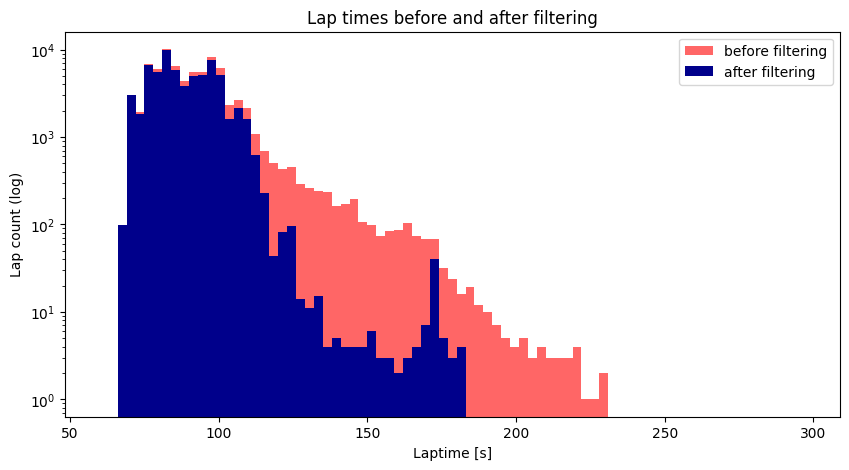

In [19]:
filtered = df.loc[~df[FLAGS].any(axis=1), "lap_duration"]

fig, ax = plt.subplots(figsize=(10, 5))
bins = range(60, 300, 3)

ax.hist(df_raw["lap_duration"], bins=bins, color="red", alpha=0.6, label="before filtering")
ax.hist(filtered, bins=bins, color="darkblue", label="after filtering")
ax.set_yscale("log")
ax.set_xlabel("Laptime [s]")
ax.set_ylabel("Lap count (log)")
ax.set_title("Lap times before and after filtering")
ax.legend()
plt.show()

Im obigen Plot wird die Verteilung der Rundenzeiten vor und nach dem Filtern der Runden auf Basis der Rennüberwachung und Rennzuständen verglichen. Es lässt sich erkennen, dass hauptsächlich Rennrunden mit höheren Rundenzeiten herausgefiltert wurden. Das bestätigt die Wirksamkeit der Maßnahme, die herausgefilterteten Rundenzeiten sind nicht repräsentativ für die Regression von Delta-Zeiten schneller Rennrunden.

In [20]:
df = df[~df[FLAGS].any(axis=1)].copy()

In [21]:
df.shape

(66028, 27)

Im Folgenden werden Regenrunden untersucht. Eine nasse Strecke beeinflusst das Fahrverhalten und den Rennverlauf stark. Weiterhin werden bei nasser Strecke Regenreifen `["INTERMEDIATE", "WET"]` eingesetzt. Diese haben ein gesondertes Regenprofil zur Verdrängung des Wassers. Diese Reifen sind langsamer als Slick-Reifen `["SOFT", "MEDIUM", "HARD"]`. Diese benannten Fälle werden ebenfalls aus den Daten herausgefiltert, da sie nicht repräsentativ für die Delta-Zeit-Prognose sind.

In [22]:
df[df['compound'].isin(['HARD','MEDIUM','SOFT'])]["rainfall"].value_counts()

rainfall
0    62625
1      355
Name: count, dtype: int64

Im Datensatz liegen 355 Rennrunden vor, in welchen mit Slick-Reifen zu Regenkonditionen gefahren wurden. 

In [23]:
df[df['compound'].isin(['INTERMEDIATE','WET'])]["rainfall"].value_counts(), df[df['compound'].isin(['INTERMEDIATE','WET'])]["rainfall"].value_counts().sum()

(rainfall
 0    1611
 1    1437
 Name: count, dtype: int64,
 np.int64(3048))

Außerdem liegen 3048 Rennrunden vor, in welchen mit Regenreifen gefahren wurde, wobei es bei 1437 Runden geregnet hat, die verlbleibenden 1611 Rennrunden wurden vermutlich zu nassen Streckenkonditionen gefahren.

In [24]:
df = df[df["compound"].isin(["HARD", "MEDIUM", "SOFT"]) & (df["rainfall"] == 0)].copy()

In [25]:
df.shape

(62625, 27)

Im Folgenden werden Stints mit wenigen Runden entfernt. Dies dient der Signalqualität des Targets. Bei kurzen Stints entsteht keine große Aussagekraft der Reifendegradation. Außerdem bilden lange Stints den Wertebereich der kurzen Stints ebenfalls ab, weshalb die Information in dem Fall redundant ist und kein Verlust entsteht.

In [26]:
df.groupby("stint_id").size().describe()

count    3203.000000
mean       19.551983
std        10.982726
min         1.000000
25%        11.000000
50%        18.000000
75%        26.000000
max        75.000000
dtype: float64

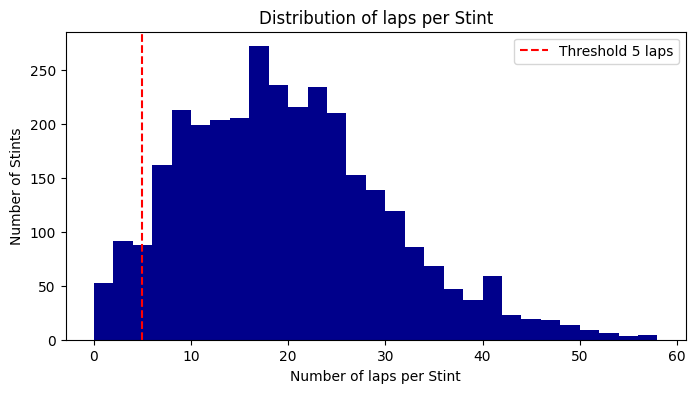

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(df.groupby("stint_id").size(), bins=range(0, 60, 2), color="darkblue")
ax.axvline(5, color="red", linestyle="--", label="Threshold 5 laps")
ax.set_xlabel("Number of laps per Stint")
ax.set_ylabel("Number of Stints")
ax.set_title("Distribution of laps per Stint")
ax.legend()
plt.show()

Im Plot ist erkennbar, dass die meisten Stints mehr als 5 Runden lang sind, entsprechend ist die Schwelle von 5 Rennrunden angebracht.

In [28]:
stint_laps = df.groupby("stint_id")["lap_number"].transform("size")
df = df[stint_laps > 5].copy()
df.shape

(61938, 27)

## 4.2 Definition des Targets

Das Target ist die Delta zur Referenzrunde des Stints. Durch diese Modellierung fallen alle innerhalb eines Stints konstanten Einlüsse heraus. Fahrer, Auto, Strecke und Setup werden als konstant angenommen und übrig bleibt die relative Veränderung der Rundenzeit, welche die meiste Information zum Reifenzustand trägt. Es liegt nahe die Anfangsrunde eines Stints als Referenzrunde zu wählen. Da jedoch die erste Runde nach einem Stint aufgrund von Verkehr, Fahrfehlern, Reifen-Warmup oder anderen Einflüssen nicht zwangsläufig ideal ist, wird der Median der ersten drei Rennrunden gewählt. Dies macht die Referenz robuster. 

In [29]:
df = df.sort_values(["stint_id", "stint_age"])
reference_lap = df.groupby("stint_id").head(3).groupby("stint_id")["lap_duration"].median()
df["delta_lap_time"] = df["lap_duration"] - df["stint_id"].map(reference_lap)

In [30]:
print("Percentiles:")
print(df["delta_lap_time"].quantile([0.005, 0.01, 0.99, 0.995, 0.999]).round(2))

Percentiles:
0.005    -6.74
0.010    -4.86
0.990     6.85
0.995    10.67
0.999    34.37
Name: delta_lap_time, dtype: float64


Die Ausgabe zeigt die Perzentile der Delta-Werteverteilung. Es ist ersichtlich, dass 0.5% der Werte kleiner als -6,74 Sekunden sind und 0.5% Der Werte größer als 10,67 Sekunden sind. Es wird angenommen, dass es sich bei den Werten außerhalb um Ausreiser handelt, die keinen Aussage-Mehrwert für die Untersuchung bringen. Diese Untersuchung ist streckenübergreifend zulässig, da die Delta-Zeit durch die Bereinigung der absoluten Rundenzeit streckennormiert ist. Die folgende Abbildung zeigt die Verteilung aller Delta-Zeiten.

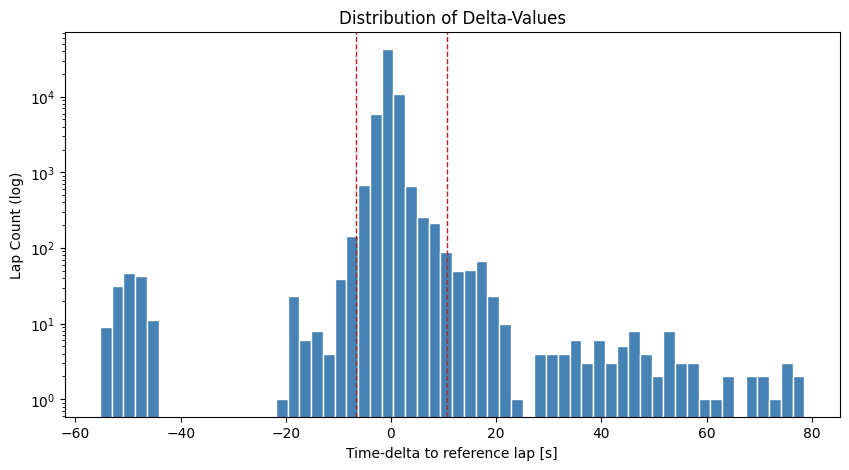

In [31]:
upper_bound = 10.67
lower_bound = -6.74

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(df["delta_lap_time"], bins=60, color="steelblue", edgecolor="white")
ax.set_yscale("log")
ax.axvline(lower_bound, color="firebrick", linestyle="--", linewidth=1)
ax.axvline(upper_bound, color="firebrick", linestyle="--", linewidth=1)
ax.set_xlabel("Time-delta to reference lap [s]")
ax.set_ylabel("Lap Count (log)")
ax.set_title("Distribution of Delta-Values")
plt.show()

In [32]:
df = df[df["delta_lap_time"].between(lower_bound, upper_bound)].copy()

In [33]:
df.shape

(61318, 28)

Weiterhin wird die Rennstartrunde aus dem Datensatz entfernt. Die erste Runden wird mit einem stehenden Start begonnen und ist dadurch und durch Gedränge beim Start deutlich langsamer als eine repräsentative normale Rennrunde. Die Rennstartrunde würde die Zielgröße verzerren.

In [34]:
df = df[df["lap_number"] != 1].copy()

In [35]:
df.shape

(60736, 28)

Die folgende Tabelle zeigt eine Zusammenfassung der Datenfilterung.

| Filterschritt | Runden | Entfernt | Verbleibend |
|---|---|---:|---:|
| Rohdaten | 77.322 | – | 100,0 % |
| NaN entfernt | 77.096 | 226 | 99,7 % |
| Flags (Out/In-Lap, SC/VSC/Yellow/Red) | 66.028 | 11.068 | 85,4 % |
| Regen / Slick-Filter | 62.625 | 3.403 | 81,0 % |
| Kurze Stints (≤5 Runden) | 61.938 | 687 | 80,1 % |
| Delta-Ausreißer | 61.318 | 620 | 79,3 % |
| Rennstartrunde | 60.736 | 582 | 78,5 % |

## 4.3 Feature: race_progress

Die Spritmenge sinkt kontinuierlich über den Rennverlauf. Dadurch sinkt auch das Gewicht des Bolliden und Runden werden tendenziell schneller. Dieser Effekt wirkt dem Reifenabbau entgegen. Damit dieser Effekt sauber modelliert werden kann, wird der Rennfortschritt als Feature ergänzt. Der Rennfortschritt wird hierbei als Quotient aus der Anzahl an absolvierten Runden und der Renndistanz gebildet.

In [36]:
max_lap = df_raw.groupby("session_key")["lap_number"].max()
df["race_progress"] = df["lap_number"] / df["session_key"].map(max_lap)

In [37]:
df["race_progress"].describe()

count    60736.000000
mean         0.513499
std          0.277997
min          0.025316
25%          0.274510
50%          0.512821
75%          0.756410
max          1.000000
Name: race_progress, dtype: float64

Die Werteverteilung zeigt eine saubere und gleichmäßige Verteilung des Rennfortschritts.

## 4.4 Explorative Datenanalyse

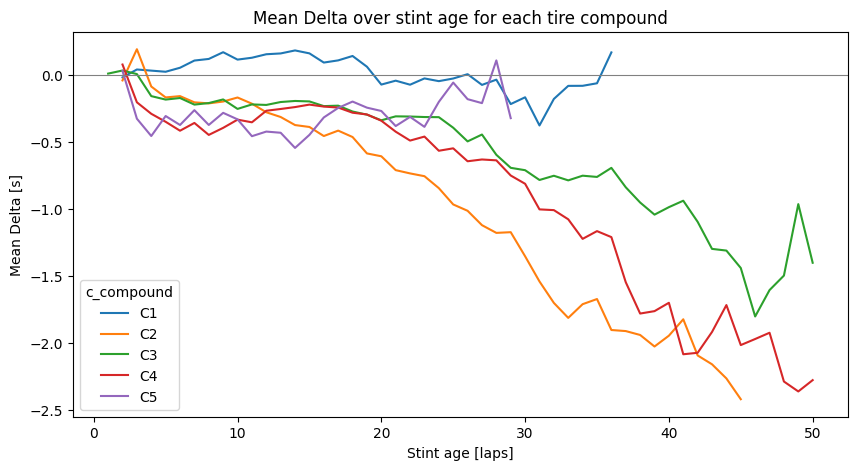

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))

for code in ["C1", "C2", "C3", "C4", "C5"]:
    sub = df[df["c_compound"] == code]
    trend = sub.groupby("stint_age")["delta_lap_time"].mean()
    trend = trend[sub.groupby("stint_age").size() >= 20]
    ax.plot(trend.index, trend.values, label=code)

ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Stint age [laps]")
ax.set_ylabel("Mean Delta [s]")
ax.set_title("Mean Delta over stint age for each tire compound")
ax.legend(title="c_compound")
plt.show()

Der obige Plot zeigt die mittlere Delta-Zeit im Verlauf des Stint-Alters für jede Reifenmischung. Es ist erkennbar, dass je später Älter der Stint desto schneller wird die Rennrunde. Dieser Effekt ist auf die bereits erwähnte sinkende Spritmenge sowie Streckenevolution zurückzuführen. Der Asphalt wird im Laufe eines Formel-1-Rennens durch den Reifenabrieb immer griffiger, das Gummi der Reifen setzt sich in den Asphaltporen ab, wodurch die Reifen und das Fahrzeug mehr Bodenhaftung hat. Das führt zusätzlich zu der sinkenden Spritmenge zu schnelleren Rennrunden im Verlauf des Rennens.

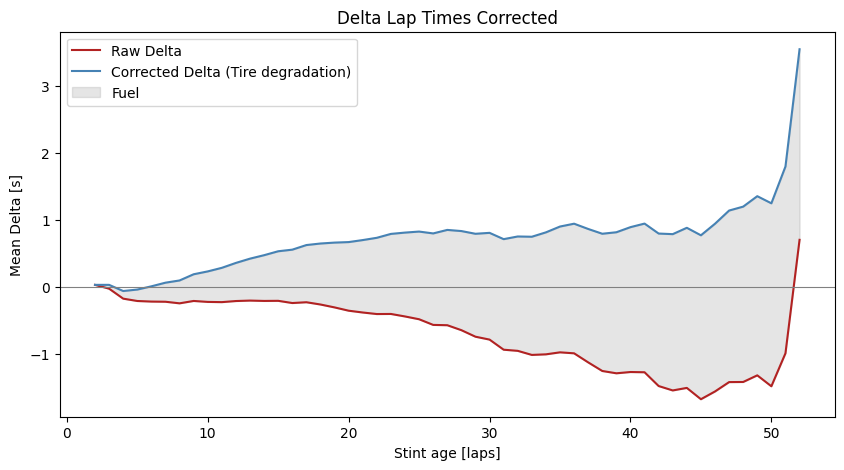

In [39]:
k = 0.057

df["delta_fuel_corr"] = df["delta_lap_time"] + k * (df["stint_age"] - 2)

raw = df.groupby("stint_age")["delta_lap_time"].mean()
corr = df.groupby("stint_age")["delta_fuel_corr"].mean()
n = df.groupby("stint_age").size()

raw, corr = raw[n >= 30], corr[n >= 30]
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(raw.index, raw.values, color="firebrick", label="Raw Delta")
ax.plot(corr.index, corr.values, color="steelblue", label="Corrected Delta (Tire degradation)")
ax.fill_between(raw.index, raw.values, corr.values, color="grey", alpha=0.2, label="Fuel")
ax.axhline(0, color="grey", linewidth=0.8)

ax.set_xlabel("Stint age [laps]")
ax.set_ylabel("Mean Delta [s]")
ax.set_title("Delta Lap Times Corrected")
ax.legend()
plt.show()

Der obige Plot zeigt die Delta-Rundenzeiten, bereinigt vom Einfluss des Sprits und der Streckenevolution. Es ist zu erwähnen, dass es sich lediglich um eine grobe lineare Schätzung eines linearen Faktors handelt, welcher zu Visualisierungszwecken gewählt wurde. Es wird angenommen, dass die Spritmenge im Verlaufe des Rennens linear verbraucht wird. Weiterhin wird angenommen, dass der Tankbereich annähernd linear von der Masse abhängt. Das FIA-Reglement legt fest, dass die maximale Renn-Spritmasse auf 110 kg begrenzt ist. Daraus ergibt sich bei einer beispielhaften Rundenzahl von 57 Runden eine Massenreduktion durch Spritverbrauch von $$c = \frac{110\ kg}{57\ Runden} = 1,9\ \frac{kg}{Runde}$$ In Fachkreisen wird weiterhin grob geschätzt von 0,3 Sekunden Zeitverlust pro 10 Kilogramm Sprit pro Runde ausgegangen. Daraus folgt $$f = 0,03\ \frac{s}{kg}$$ und es lässt sich ein linearer Faktor von $$k = f \cdot c = 0,03\ \frac{s}{kg} \cdot 1,9\ \frac{kg}{Runde} = 0,057 \frac{s}{Runde}$$ ermitteln. Dieser Wert wird im obigen Plot verwendet, um modellhaft den Einfluss des Sprits herauszurechnen und den tatsächlichen Einfluss des Reifenverschleißes darzustellen. Die rote linie enthält das rohe Delta, welches tatsächlich so aus den Daten entstanden ist. Aus der blauen Linie wird die Spritmenge herausgerechnet enthält jedoch noch die (negative) Streckenevolution und unterschätzt den reinen Reifenabbau daher eher, die dargelegte Schlussfolgerung wird dadurch nur stärker.

## 4.5 Team-Mapping

Wie bereits erwähnt wurden einige Teams über Seasons umbenannt. Um die Datengewichtung nicht zu verzerren und eine Vergleichbarkeit der Teams zu gewährleisten werden die Teamnamen angepasst. 

In [40]:
team_mapping = {
    "Alfa Romeo": "Sauber", 
    "Kick Sauber": "Sauber",
    "AlphaTauri": "Racing Bulls", 
    "RB": "Racing Bulls", 
    "Racing Bulls": "Racing Bulls",
}

df["team_id"] = df["team_id"].replace(team_mapping)

## 4.6 Abschluss

Mit diesem Schritt kann nun der finale Datensatz geschaffen werden.

In [41]:
features = [
    "stint_age", 
    "tyre_age_at_start", 
    "c_compound",
    "team_id", 
    "track_id", 
    "year", 
    "driver_number",
    "air_temperature", 
    "track_temperature", 
    "humidity", 
    "race_progress"
]
target = "delta_lap_time"
group = "stint_id"

model_df = df[features + [target, group]].copy()

Die Spalte `group` wird zusätzlich zum Target und den Features erstellt. Sie wird benötigt, da die Runden innerhalb eines Stints keine unabhängigen Werte enthalten. Sie teilen dieselbe Referenzrunde, denselben Fahrer, dasselbe Auto, dieselbe Strecke und diesselbe Reifenmischung. Aufeinanderfolgende Runden unterscheiden sich nur minimal und ein zufälliger zeilenweiser Split würde dazu führen, dass dem Modell in seinen Trainingsdaten nahzu identische Nachbarn vorlägen, was zu Data Leakage führen würde.

In [42]:
model_df.head()

,stint_age,tyre_age_at_start,c_compound,team_id,track_id,year,driver_number,air_temperature,track_temperature,humidity,race_progress,delta_lap_time,stint_id
53101,2.0,0.0,C2,Alpine,46,2025,10,14.3,21.0,77.0,0.037736,0.000,10_10006_1
53121,3.0,0.0,C2,Alpine,46,2025,10,14.3,20.8,77.0,0.056604,-0.903,10_10006_1
53141,4.0,0.0,C2,Alpine,46,2025,10,14.3,20.9,77.0,0.075472,-1.150,10_10006_1
53161,5.0,0.0,C2,Alpine,46,2025,10,14.3,20.7,77.0,0.094340,-1.304,10_10006_1
53181,6.0,0.0,C2,Alpine,46,2025,10,14.3,20.7,77.0,0.113208,-1.008,10_10006_1


In [43]:
categorical = ["c_compound", "team_id", "track_id", "year", "driver_number"]
numerical = ["stint_age", "tyre_age_at_start", "air_temperature", "track_temperature", "humidity", "race_progress"]

print(model_df.shape[0], "Laps,", model_df[group].nunique(), "Stints")

model_df[numerical + [target]].describe()

for col in ["c_compound", "team_id", "year"]:
    print(model_df[col].value_counts(), "\n")

60736 Laps, 2970 Stints
c_compound
C3    26330
C4    15334
C2    11000
C1     5522
C5     2508
C6       42
Name: count, dtype: int64 

team_id
McLaren            6367
Mercedes           6293
Ferrari            6230
Red Bull Racing    6185
Haas F1 Team       6160
Racing Bulls       6072
Aston Martin       6002
Sauber             5943
Alpine             5882
Williams           5602
Name: count, dtype: int64 

year
2025    21027
2024    20305
2023    19404
Name: count, dtype: int64 



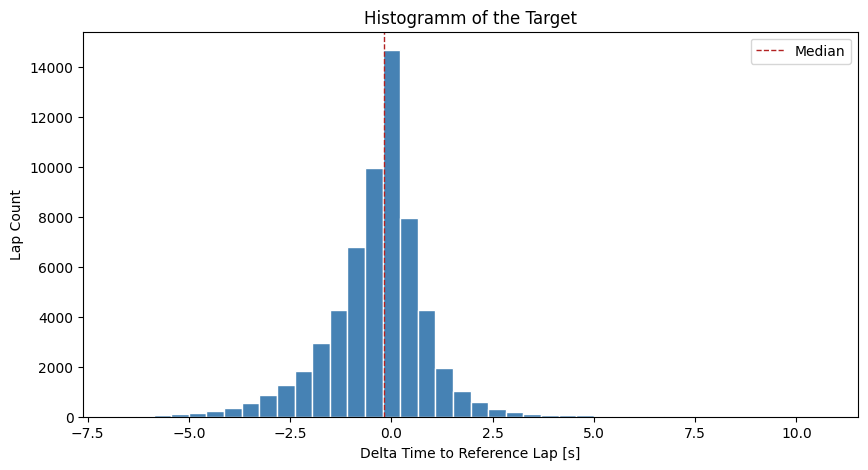

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(model_df[target], bins=40, color="steelblue", edgecolor="white")
ax.axvline(model_df[target].median(), color="firebrick", linestyle="--", linewidth=1, label="Median")
ax.set_xlabel("Delta Time to Reference Lap [s]")
ax.set_ylabel("Lap Count")
ax.set_title("Histogramm of the Target")
ax.legend()
plt.show()

Das obige Histogramm zeigt das Target im finalen, bereinigten Datensatz. Die Verteilung ist um null verteilt, die Bildung der Referenz zum Stint Beginn hat die Streckenunterschiede herausgerechent und für eine Vergleichbarkeit gesorgt. Auffällig ist eine leichte linksschiefe, der negative bereich ist breiter als der positive. Das ist konsistent mit der zuvor herausgearbeiteten Erkenntniss, dass der Spritabbau und die Streckenevolution die Rundenzeiten über einen Stint im Mittel stärker senken, als der Reifenverschleiß sie erhöht.

# 5. Split und Baselines

In diesem Kapitel werden die ersten Modelle definiert, um eine erste Referenz für die Komplexität des Datensatzes zu gewinnen. Dazu werden zwei Baselines und zwei Lernalgorithmen definiert, der Datensatz in Trainings, Validierungs- und Testdaten aufgeteilt und die vier Modelle anhand der in Kapitel 1 festgelegte Metriken evaluiert. 

## 5.1 Baselines

Die zwei Baselines dienen als Referenzpunkte, gegen die sich die eigentlichen Algorithmen behaupten müssen. 

**B1:** Vorhersage des Trainings-Mittelwerts der Zielgröße. Dieses Modell lernt keine Zusammenhänge und erreich er Definition einen $R^2 = 0$ und markiert die Untergrenze, welche ein Modell erreichen sollte,

**B2:** Eine lineare Regression mit Standard-Parametern. Sie lernt einen linearen Zusammenhang zwischen Features und Target und zeigt wie weit ein einfaches Modell trägt. Der Abstand zwischen B1 und B2 legt dar, wie viel des Signals bereits rein linear erfassbar ist.

## 5.2 Algorithmen

Als Lernalgorithmen werden bewusst zwei unterschiedliche Modellfamilien gewählt.

**A1 Gradient Boosting (`HistGradientBoostingRegressor`):** Als baumbasiertes Ensemble kann es nichtlineare Zusammenhänge und Interaktionen abbilden, etwa zwischen Reifenmischung und Stint-Alter, was für die Bestimmung der Reifendegradation von hoher Bedeutung ist. Gradient Boosting trainiert sequenziell Bäume, wobei jeder neue Baum den Residualfehler des vorherigen lernt. Die Lernrate skaliert dabei den Beitrag jedes Baums um kontrolliert und ohne Overshooting an den echten Wert heranzutasten. Die finale Vorhersage ist die Summe aller Baumvorhersagen. Histogram Gradient Boosting stammt aus der Familie der Gradient Boosting Algorithmen, ist aber weniger rechenintensiv. Anstelle alle Datenpunkte für einen möglichen Split eines Astes zu untersuchen wird der Datensatz in n Bins aufgeteilt und nur die Grenzen dieser Bins werden für einen möglichen Split berücksichtigt. Diese Vereinfachung reduziert bei großen Datensätzen die Rechenintensivität zu niedrigen Qualitsätskosten.

**A2 k-Nearest-Neighbors (`KNEighborsRegressor`):** Trifft Vorhersagen allein anhand der Ähnlichkeit zu den nächstgelegenen Trainingsbeispielen und stellt damit einen grundlegend anderen Ansatz dar. Der Vergleich beider Algorithmen zeigt, ob ein Ensemble einem einfacheren Ähnlichkeitsmodell überlegen ist. KNN trifft seine Entscheidungen distanzbasiert, meist über den euklidischen Abstand. Ein echtes Training existiert bei KNN nicht, das Modell speichert einfach die Trainingsdatenpunkte und berechnet für die k nächsten Datenpunkte den Mittelwert der Zielwerte für einen neuen vorherzusagenden Punkt aus.

## 5.3 Notwendige Transformationen

Die gewählten Algorithmen stellen unterschiedliche Anforderungen an die Daten. Zwei Transformationen sind relevant:

**Kategorische Kodierung (One-Hot):** Alle Modelle benötigen numerische Eingaben und können die kategorischen Merkmale (`c_compound`, `team_id`, `track_id`, `year`, `driver_number`) nicht direkt verarbeiten. Diese werden per One-Hot-Encoding in binäre Spalten überführt. Da durch einen gruppierten Split seltene Kategorien (etwa Ersatzfahrer) ausschließlich im Test auftreten können, wird `handle_unknown="ignore"` gesetzt, damit im Training ungesehene Datenpunkte nicht zu Fehlern führen.

**Standardisierung:** `KNeighborsRegressor` trifft Vorhersagen anhand von Distanzen. Ohne Skalierung würden Merkmale mit großem Wertebereich (z. B. `humidity` 17–92) solche mit kleinem Wertebereich (z.B. `stint_age`) verzerren. Eine Standardisierung der numerischen Merkmale ist für KNN daher zwingend.

Sämtliche Transformationen werden innerhalb einer `Pipeline` ausgeführt und ausschließlich auf den Trainingsdaten gefittet, um Data Leakage zu vermeiden.

## 5.4 Split

Die Daten werden in ein Trainings-, Validierungs, Testsplit aufgeteilt (50%, 25%, 25%). Der Trainingsanteil dient dem Modell Training, der Validierungsanteil dem Hyperparameter Tuning und der Testanteil der finalen Bewertung. Der `random_state` wird fix mit dem Wert 42 versehen damit alle Ergebnisse reproduzierbar bleiben. Wichtig ist den Split nach Stint zu gruppieren statt zufällig rundenweise durchzuführen. Alle Runden eines Stints teilen sich dieselbe Referenzrunde und sind dadurch stark voneinander abhängig. Wenn ein Split im Trainings- und Testdatenset landet, dann kennt das Modell die Daten im Test im Prinzip schon und würde gesehene Information wiedererkennen. Das führt zu Data Leakage, was das Modell zu gut performen lässt. Über die Spalte `stint_id` wird jeder Stint genau einer der Drei Splits zugewiesen. 

In [45]:
RANDOM_STATE = 42

stints = model_df[group].drop_duplicates().to_list()
train_stints, temp_stints = train_test_split(stints, train_size=0.5, random_state=RANDOM_STATE)
val_stints, test_stints = train_test_split(temp_stints, train_size=0.5, random_state=RANDOM_STATE)

train = model_df[model_df[group].isin(train_stints)]
val = model_df[model_df[group].isin(val_stints)]
test = model_df[model_df[group].isin(test_stints)]

X_train, y_train = train[features], train[target]
X_val, y_val = val[features], val[target]
X_test, y_test = test[features], test[target]

## 5.5 Pipelines und Evaluation

Es werden in `ColumnTransformer` zunächst die kategorischen Features One-Hot encoded, für KNN werden die Daten noch mit dem `StandardScaler` skaliert. Alle Modelle werden mit Default-Parametern trainiert und die Bewertung erfolgt mit den Metriken MAE und $R^2$.

In [46]:
one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocess = ColumnTransformer([
    ("cat", one_hot, categorical),
    ("num", "passthrough", numerical),
])

preprocess_scaled = ColumnTransformer([
    ("cat", one_hot, categorical),
    ("num", StandardScaler(), numerical),
])

models = {
    "B1 Dummy": Pipeline([("prep", preprocess), ("model", DummyRegressor(strategy="mean"))]),
    "B2 Linear": Pipeline([("prep", preprocess), ("model", LinearRegression())]),
    "A1 GradientBoosting": Pipeline([("prep", preprocess), ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
    "A2 KNN": Pipeline([("prep", preprocess_scaled), ("model", KNeighborsRegressor())]),
}

In [47]:
results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({"Model": name, "MAE": mean_absolute_error(y_test, pred), "R2": r2_score(y_test, pred)})

results = pd.DataFrame(results).set_index("Model").round(3)
results

,MAE,R2
Model,,
B1 Dummy,0.884,-0.001
B2 Linear,0.778,0.216
A1 GradientBoosting,0.642,0.447
A2 KNN,0.844,0.062


Der Mittelwert-Prädiktor erreicht erwartungsgemäß ein Bestimmtheitsmaß von $R^2 = 0$, da das Bestimmtheitsmaß den Fehler in Bezug auf den Mittelwert und entsprechend performt der Dummy-Regressor nicht. Der mittelere Absolute Fehler $MAE = 0.884$ ist der Referenzfehler, an dem die anderen Modelle zu messen sind. Ein einfaches lineares Modell kann bereits 20 % der Varianz in den Daten erklären, es steckt also etwas lernbares in den Daten. Gradient Boosting ist eindeutig das stärkste Modell ($MAE = 0.642$, $R^2 = 0.447$) und zeigt eine deutliche Verbesserung in der erklärten Varianz sowie im mittleren absoluten Fehler. KNN hingegen ist kaum besser als der Dummy-Regressor. Die hohe Dimensionalität hervorgerufen durch die One-Hot-Features bereitet dem Modell scheinbar Schwierigkeiten. Das aussichtsreichste Modell ist augenscheinlich das Gradient Boosting, es kann die hohe Dimensionalität im Datensatz am Besten handhaben.

# 6. Hyperparameter und Modellwahl

Es werden nun die beiden Algorithmen $A_1$ und $A_2$ optimiert. Für Gradient Boosting werden die Hyperparamter `learning_rate` und `max_depth` optimiert. Die Lernrate skaliert den Betrags jedes Baums zur finalen Vorhersage. Eine kleine Lernrate tastet sich in vielen kleinen Schritten an den echten Wert heran und verhindert Overshooting. `max_depth` begrenzt die maximale Tiefe jedes einzelnen Baums im Ensemble. Ein tiefer Baum kann komplexe Interaktionen zwischen Features abbilden, neigt aber zu Overfitting weil er sich eng an die Trainingsdaten anpasst. Ein flacher Baum ist stabiler und generalisiert besser, kann aber relevante nichtlineare Zusammenhänge verpassen.

Für jeden Hyperparameter wird zunächst eine Valdidation Curve pber einen weitern Bereich erstellt, um die Region des Optimums festzustellen. Daraus wird dann ein Grid abgeleitet, welches den Wertebereich nochmal genauer nach einer optimalen Hyperparameter Kombination durchsucht.

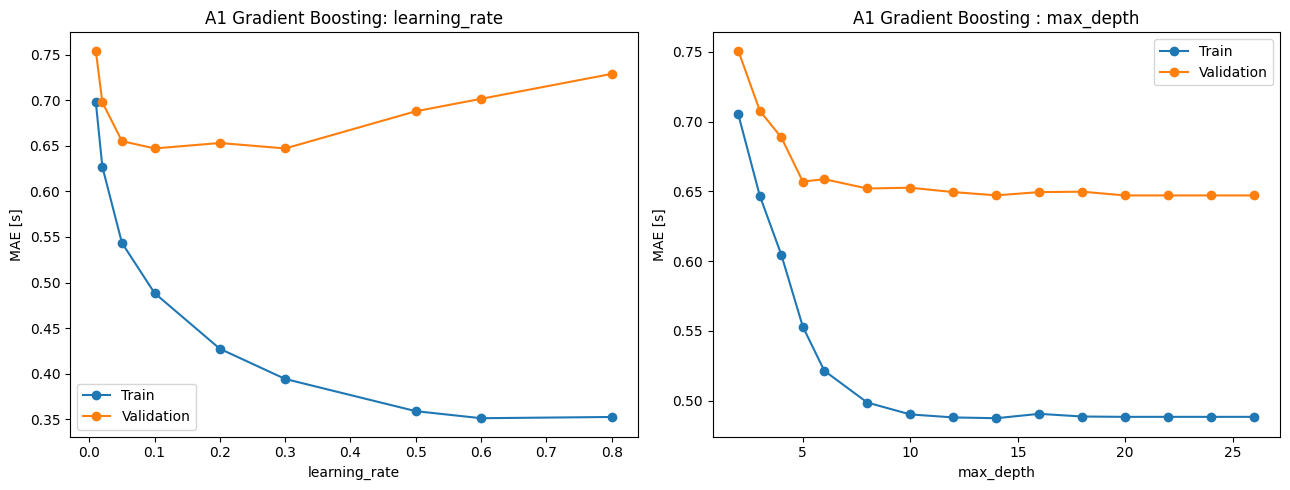

In [48]:
def val_curve(pipe, param, values):
    train_mae, val_mae = [], []
    for v in values:
        m = clone(pipe).set_params(**{param: v}) # create a new fresh copy of the pipelione
        m.fit(X_train, y_train)
        train_mae.append(mean_absolute_error(y_train, m.predict(X_train)))
        val_mae.append(mean_absolute_error(y_val, m.predict(X_val)))
    return train_mae, val_mae

learning_rates = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.8]
max_depths = [2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26]

tr_lr, va_lr = val_curve(models["A1 GradientBoosting"], "model__learning_rate", learning_rates)
tr_md, va_md = val_curve(models["A1 GradientBoosting"], "model__max_depth", max_depths)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(learning_rates, tr_lr, marker="o", label="Train")
axes[0].plot(learning_rates, va_lr, marker="o", label="Validation")
axes[0].set_xlabel("learning_rate")
axes[0].set_ylabel("MAE [s]")
axes[0].set_title("A1 Gradient Boosting: learning_rate")
axes[0].legend()

axes[1].plot(max_depths, tr_md, marker="o", label="Train")
axes[1].plot(max_depths, va_md, marker="o", label="Validation")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("MAE [s]")
axes[1].set_title("A1 Gradient Boosting : max_depth")
axes[1].legend()

plt.tight_layout()
plt.show()

**learning_rate:** Der Trainingsfehler fällt mit steigender Lernrate, das Modell passt sich also immer mehr den Trainingsdaten an. Der Fehler auf den Validierungsdaten hingegen ist bei sehr kleiner Rate hoch was Underfitting aufzeigt. Das Minimum des Fehlers liegt bei ca. 0.05 - 0.1 und steigt ab 0.3 wieder an. Ein sinvoller zu untersuchender Bereich liegt um 0.1. Der immer größer werdende Abstand zwischen Trainings- und Validierungskurve deutet auf Overfitting hin.

**max_depth:** Auch hier fällt der Trainingsfehler monoton je tiefer die Bäume sind. Der Validierungsfehler sinkt bis zu einer Tiefe von ca. 5 - 6, danach läuft es in ein Plateau. Tiefere Fehler bringen also keinen Mehrwert mehr in Bezug auf den Fehler und das Modell scheint auch zu Overfitten.

Es werden entsprechend der Lernkurven Parameterwerte gewählt, die in den Bereichen der Minima liegen, ohne großes Overfitting zu verursachen. Aus den Kurven wird je Algorithmus ein Grid im Bereich des Validierungsminimums abgeleitet. Als Strategie dient eine Gittersuche (`GridSearchCV`). 

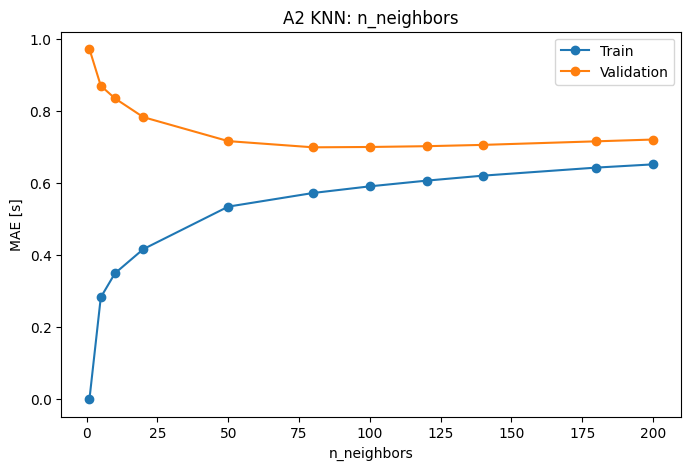

In [49]:
n_neighbors = [1, 5, 10, 20, 50, 80, 100, 120, 140, 180, 200]

tr_k, va_k = val_curve(models["A2 KNN"], "model__n_neighbors", n_neighbors)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(n_neighbors, tr_k, marker="o", label="Train")
ax.plot(n_neighbors, va_k, marker="o", label="Validation")
ax.set_xlabel("n_neighbors")
ax.set_ylabel("MAE [s]")
ax.set_title("A2 KNN: n_neighbors")
ax.legend()
plt.show()

Bei `n_neighbors = 1` ist der Trainingsfehler praktisch bei null, was daran liegt, dass jeder Punkt auch gleichzeitig sein eigener Nachbar ist. Es liegt also Overfitting vor. Mit wachsendem k steigt der Trainingsfehler und der Validierungsfehler fällt bis er bei für ca. k = 80 sein Minimum erreicht und dann wieder sehr leicht ansteigt. 

In [50]:
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

test_fold = [-1] * len(X_train) + [0] * len(X_val)
ps = PredefinedSplit(test_fold)
grids = {
    "A1 GradientBoosting": {"model__learning_rate": [0.05, 0.07, 0.08, 0.09, 0.1, 0.12, 0.14, 0.16, 0.18, 0.2], "model__max_depth": [2, 3, 4, 5, 6, 7, 8, 9]},
    "A2 KNN": {"model__n_neighbors": [40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 110, 120]},
}
best = {}
for name in grids:
    search = GridSearchCV(models[name], grids[name], scoring="neg_mean_absolute_error", cv=ps)
    search.fit(X_trainval, y_trainval)
    best[name] = search.best_estimator_
    print(name, search.best_params_, round(-search.best_score_, 3))

A1 GradientBoosting {'model__learning_rate': 0.12, 'model__max_depth': 8} 0.64
A2 KNN {'model__n_neighbors': 90} 0.698


In [51]:
tuned = []
for name, pipe in best.items():
    pred = pipe.predict(X_test)
    tuned.append({"Modell": name, "MAE":
mean_absolute_error(y_test, pred), "R2": r2_score(y_test, pred)})
    
tuned = pd.DataFrame(tuned).set_index("Modell").round(3)
comparison = results.join(tuned, lsuffix="(Default)", rsuffix="(tuned)")
comparison

,MAE(Default),R2(Default),MAE(tuned),R2(tuned)
Model,,,,
B1 Dummy,0.884,-0.001,NaN,NaN
B2 Linear,0.778,0.216,NaN,NaN
A1 GradientBoosting,0.642,0.447,0.635,0.455
A2 KNN,0.844,0.062,0.674,0.392


Es ist erkennbar, dass das Hyperparametertuning unterschiedlichen Einfluss auf die beiden Modelle hat. Die Performance von Gradient Boosting verbessert sich nur minimal. Augenscheinlich war das Modell bereits mit den Default-Werten der Hyperparameter nahe am Optimum. KNN hingegen hat sehr stark vom Hyperparametertuning profitiert. Das Bestimmtheitsmaß ist von 6 % auf fast 40 % angestiegen. Trotz der starken Verbesserung liefer das Gradient Boosting die besseren Ergebnisse. Das Hyperparametertuning hat gezeigt, dass der Alogrithmus zuverlässig und robust ist. Weiterhin hat der `HistGradientBoostingRegressor` die Vorteile von niedrigerer Rechenintensivität geringerer Komplexität in Bezug auf die Wahl der Hyperparameter. Es benötigt keine Skalierung und ist durch die aufgezählten Eigenschaften gerade bei Formel-1-Rennen im Live-Einsatz praktikabler. Somit wird für die finale Untersuchung `HistGradientBoostingRegressor` in seiner besten Hyperparameter Kombination (`learning_rate = 0.12`, `max_depth = 8`) als das finale Modell M gewählt.

Im folgenden Task wird mittels Bootstrap geprüft ob das Modell, ob die geringe Verbesserung des mittleren absoluten Fehlers auf einen unglücklichen Split der Daten zurückzuführen ist, oder ob das Modell tatsächlich so stabil ist.

# 7. Bootstrap

Um die Stabilität des finalen Modells zu beurteilen wird eine Bootstrap durchgeführt. Aus den kombinierten Trainings- und Validierungsdaten werden Stichproben gezogen, das Modell auf jeder Stichprobe neu trainiert und auf dem Testset bewertet. Daraus lässt sich ableiten wie verlässlich die Performance des Modells ist. Wichtig zu erwähnen ist, dass mit dem vorliegenden Problem auf Stint ebene gesampelt werden muss, da Runden innerhalb eines Stints voneinander abhängig sind. 

In [52]:

M = clone(best["A1 GradientBoosting"])

trainval = pd.concat([train, val])
trainval_stints = trainval[group].unique()

n_iterations = 30
rng = np.random.default_rng(RANDOM_STATE)

boot_mae, boot_r2 = [], []
for _ in range(n_iterations):
    sample_stints = rng.choice(trainval_stints, size=len(trainval_stints), replace=True)
    sample = pd.concat([trainval[trainval[group] == s] for s in sample_stints])

    M.fit(sample[features], sample[target])
    pred = M.predict(X_test)
    boot_mae.append(mean_absolute_error(y_test, pred))
    boot_r2.append(r2_score(y_test, pred))

boot_mae, boot_r2 = np.array(boot_mae), np.array(boot_r2)

In [53]:
def summary(name, arr):
    lo, hi = np.percentile(arr, [2.5, 97.5])
    print(f"{name}: Mittel {arr.mean():.3f}, Std {arr.std():.3f}, Range [{arr.min():.3f}, {arr.max():.3f}], 95%-CI [{lo:.3f},{hi:.3f}]")

MAE: Mittel 0.654, Std 0.007, Range [0.642, 0.666], 95%-CI [0.644,0.665]
R2: Mittel 0.427, Std 0.013, Range [0.388, 0.447], 95%-CI [0.400,0.447]


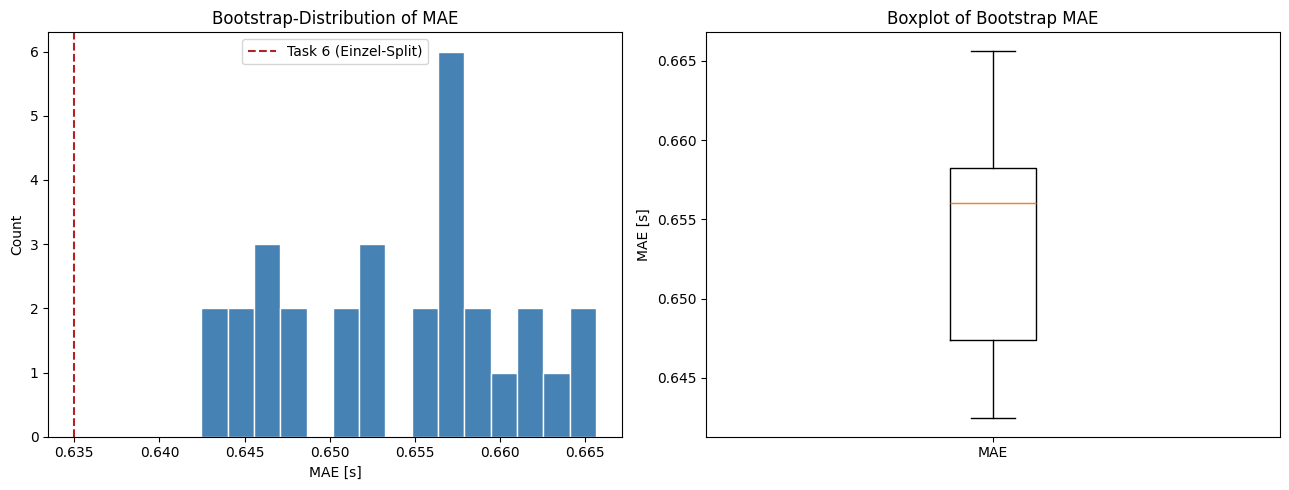

In [54]:


summary("MAE", boot_mae)
summary("R2", boot_r2)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(boot_mae, bins=15, color="steelblue", edgecolor="white")
axes[0].axvline(0.635, color="firebrick", linestyle="--", label="Task 6 (Einzel-Split)")
axes[0].set_xlabel("MAE [s]")
axes[0].set_ylabel("Count")
axes[0].set_title("Bootstrap-Distribution of MAE")
axes[0].legend()

axes[1].boxplot(boot_mae, tick_labels=["MAE"])
axes[1].set_ylabel("MAE [s]")
axes[1].set_title("Boxplot of Bootstrap MAE")

plt.tight_layout()
plt.show()


Der mittlere absoulte Fehler liegt im Mittel bei 0.654 und hat eine Standardabweichung von 0.007. Das Bestimmtheitsmaß liegt bei 0.427 mit einer Standardabweichung von 0.013. Die Standardabweichung des MAEs liegt bei rund 1 %. Es lässt sich daraus herleiten, dass das Modell unabhängig vom gesehenen Stint die Testleistung nahzu konstant bleibt. Das Modell ist damit stabil und zuverlässig. Auffällig ist, dass die Leistung des Einzelsplits aus Aufgabe 6 außerhalb und unter der Bootstrap-Verteilung liegt. Das ist darauf zurückzuführen, dass das Bootstrap lediglich Stichproben, des Datensatzes sieht, die sich teilweise überschneiden. Jedes Bootstrap trainiert auf weniger unterschiedlichen Daten, als es das Modell beim Einzelsplit getan hat, welches auf dem vollständigen Datensatz zurückgreifen konnte. Weniger Datenvielfalt führt zu schlechterer Generalisierung, vorausgesetzt die Datenqualität ist konstant. Daraus resultieren dann schlechtere Scores für die Metriken. 

Der Bootstrap hat eine etwas konservativere Schätzung der Modelleistung hervorgebracht. Es lässt sich erkennen, dass der Einzelsplit etwas optimistisch bewertet wurde. Der unterschied zwischen 0,02 s liegt, jedoch in einem vertretbaren Bereich und zeigt, dass das Modell robust ist.  

# 8. Abschluss

## 8.1 Zusammenfassung und Ergebnisse

Ziel des Projekts war ein Modell, das vorhersagt, wie sich die Rundenzeit eines Fahrers über einen Reifenstint verändert. Aus rund 77.000 Rohrunden der Saisons 2023 bis 2025 entstand nach einer schrittweisen Filterung ein bereinigter Datensatz von rund 60.000 Rennrunden. Als Target diente nicht die absolute Rundenzeit, sondern der Abstand der akutellen Runde zu einer Referenzrundenzeit zu Beginn des Stints. Dadurch fallen alle über einen Stint konstanten Einflüsse wie Fahrer, Auto, Strecke, und Setup heraus, und übrig bleibt die reine Veränderung über den Stint.

Gegen zwei einfache Vergleichsmodelle traten zwei Algroithmen an. Das beste Ergebnis lieferte das optimierte Gradient Boosting (Modell M) mit einem mittleren Fehler von 0,635 s und einem Bestimmtheitsmaß von 0,455. Es schlug sowohl die naive Mittelwert-Vorhersage (0,884 s) als auch die lineare Regression (0,778 s) deutlich. Der anschließende Bootstrap bestätigte das Modell als stabil: Über viele wiederholte Trainingsläufe blieb der Fehler mit 0,654 und einer Standardabweichung 0,007 s nahezu konstant.

Dass die lineare Regression nur etwa halb so gut abschneidet wie das finale Modell, zeigt, dass der Reifenabbau kein simpler, linearer Zusammenhang ist. Wie stark die Pace abfällt, hängt von der Reifenmischung, der Strecke und der Temperatur ab. Solche Einflüsse kann erst ein komplexeres Modell abbilden. Die durch das Bestimmtheitsmaß erklärten rund 45 % der Streuung sind ein realistisches Ergebnis. Der unerklärte Rest stammt einerseits aus nicht vorhersagbarem Rauschen einzelner Runden (Verkehr, Position, kleine Fahrfehler), andererseits daraus, dass im Delta neben dem Reifenabbau auch die sinkende Spritmenge und der steigende Grip auf der stecken, die sich nicht vollständig herausrechnen lassen.

## 8.2 Mehrwert

Das Modell liefert dem Renningieur Informationen, die aus reinen Live-Daten nicht direkt ablesebar sind, nämlich eine Streckennormierte Schätzung der reifenbedingten Pace-Entwicklung. Durch die Betrachtung des Deltas entfallen über einen Stint konstante Einflüsse (Auto, Fahrer, Strecke, Setup). Der Modelloutput ist direkt als Pace-Entwicklung in Sekunden lesbar, eine Betrachtung, die direkt in die Abwägung für oder gegen einen Boxenstopp einfließt. 

Diese Betrachtung wird durch drei Design-Entscheidungen des Modells ermöglicht. 

**Interpretierbarkeit:** Der Output wird in Sekunden pro Runde bereitgestellt, der mittelere absolute Fehler ist ebenfalls in dieser Einheit. Dadurch ist für den Renningenieur intuitiv verständlich was das Modell vorhersagt, und wie stark das Modell in der Regel abweicht. 

**Verlässlichkeit:** Die Bootstrap-Untersuchung hat gezeigt, dass die Genauigkeit über die bekannten Daten hinweg stabil ist und die Vorhersage nicht vom Zufall des Datensatzes abhängt. 

**Vorausschau:** Anstatt rückwirkend am Abfall der Rundenzeit zu erkennen, dass und wie stark die Reifen abbauen, so wie es im klassischen Sinne heute gemacht wird, lässt sich der Degradationstrend über die nächsten kommenden Runden abschätzen. Dadurch wird die Entscheidung für einen Boxenstopp von einer reaktiven zu einer antipizierenden. 

Der größte Vorteil entsteht im Boxenstoppfenster und der dazugehörigen Strategie. Ein Boxenstopp kostet in der Regel rund 20 Sekunden, innerhalb eines Rennens liegen Fahrerpositionen oftmals lediglich Zehnten Sekunden auseinander. Eine datengestützte und belastbare Degradationsprognose unterstützt bei der Entscheidung, ob sich ein Reifenwechsel lohnt oder ob es strategisch schlauer ist noch weiter auf der Strecke zu bleiben, während ein konkurrierender Fahrer bereits zu einem Boxenstopp fährt. 

## 8.3 Reflexion und Limitationen

Der mittelere Fehler des Modells (~0,65 s) liegt in der gleichen Größenordnung wie der eigentliche geschätzte Einfluss des Reifenabbaus über einen Stint, welcher in einer Größenordnung um 1 Sekunde liegt (siehe Kapitel 4.4). Für eine einzelne Runde ist die Prognose also nur sehr grob. Verlässlicher kann sie aber werden, wenn der Trend über mehrere Runden betrachtet werden, da sich dann zufällige Fehler herausmitteln können. Der Renningenieur sollte also den Wert als Trend lesen und nicht als punktgenaue Prognose. Außerdem muss immer berücksichtigt werden, dass das Delta die Überlagerung aus mehreren Effekten ist, inklusive der Reifendegradation. Sinkende Spritlast und die Streckenevolution sind Einflussfaktoren, die bei der Prognose immer mit einberechnet sind. Außerdem gilt das Modell by Design nur für saubere Trockenrunden ohne Flaggen, Safety Car und In- und Outlaps. In solchen Phasen ist das Modell nicht anwendbar.

Die Rahmenbedingungen der Aufgabenstellung beschränken diese Untersuchung auf zwei Algorithmen mit wenigen Hyperparametern. Weitere Algortihmen und umfangreicheres Hyperparameter tuning können vielversprechendere Ergebnisse liefern.

Weiterhin gilt es zu erwähnen, dass der Train-/Test-Split in dieser Untersuchung auf Basis der Stints durchgeführt wurde. Dadurch können zwei Stints desselben Rennens und damit dassselbe Auto inkl. demselben Setup, diesselbe Tagesform des Fahrers und dasselbe Wetter sowohl in den Trainings- als auch in den Testdaten landen und somit Data Leakage verursachen. Ein Split auf Ebene der Rennen oder eine zeitliche Trennung, wie bei Time-Series-Problemen könnten dieses Problem vorbeugen. Außerdem generalisiert das Modell lediglich auf bekannten Daten. Ein neuer Fahrer oder eine neue Strecke könnten lediglich über ähnliche Fahrer und Strecken im Training abgebildet werden und es gilt zu testen, ob das Modell gut genug auf diese Änderungen generalisiert. Auch ein stark geändertes Reglement in einer neuen Saison würde die Modellabbildung vermutlich schlechter perfomen lassen, da das Reglement innerhalb der Trainingsdaten als kontant abgebildet wurde. 

Zusammenfassend lässt sich sagen, dass eine sekundengenaue Prognose allein aus den zur Verfügung stehenden Daten sehr ambitioniert ist. Ohne Reifenoberflächentemperaturen, Reifendrücke und Fahrzeuglasten ist über das durchgeführte Soft-Sensing vermutlich das Limit der Prognose-Möglichkeiten erreicht. Das Bestimmtheitsmaß von 0,45 zeigt, dass die Varianz innerhalb des Datensatzes zu einem bestimmten aber keinem Vollständigen Maß widergespiegelt werden kann. Jedoch konnte eine quantitative Entscheidungshilfe für den Renneingenieur entwickelt werden, welche datengestützt Prognosen treffen und dem Team bei Strategien unterstützen kann. 

## 8.4 Future Work

Die folgenden Ansätze greifen die in Kapitel 8.3 benannten Grenzen direkt auf. 

**Feldtauglichkeit:** Bevor das Modell im Feld zum Einsatz kommt, sollte es darauf geprüft werden vergangene Rennen für zukünftige vorherzusagen. Das ist ein realistischer Test, um das Leakage-Risiko zu minimieren. Weiterhin wäre eine Konfidenzsspanne für den Renningenieur aussagekräftiger als ein scheinbar genauer Wert. Dadurch ist ersichtlich wie sicher die Prognose ist. Außerdem sollte geprüft werden, ob der Fehler des prognostizierte Wertes im erwarteten Bereich liegt. Sollte das nicht Fall sein, dann ist das ein Hinweis darauf, dass die Bedingungen nicht im Modell abgebildet sind und die Prognose nicht sehr vertrauenswürdig ist. 

**Weitere Ausarbeitungen:** Anstatt dass die Fahrer lediglich über ihre Fahrernummer dargestellt werden könnten Telemetriewerte in Bezug auf den Fahrer aus der OpenF1 API herangezogen werden. Es könnte ermittelt werden wie aggressiv ein Fahrer bremst und beschleunigt. Damit ließen sich auf Delta-Zeiten von Fahrern prognostizieren, die das Modell noch nicht gesehen hat. Gleiches gilt für die Strecke. Anstelle einem Identifier der Strecke könnte auch diese über Eigenschaften im Datensatz repräsentiert werden, beispielweise ihre Länge, die Anzahl der Kurven oder die Beschaffenheit des Asphalts. Dadurch könnte auch eine bislang unbekannte Strecke für eine Delta-Prognose genutzt werden. 


# Erklärung zur Nutzung generativer KI


Generative KI (claude.ai) wurde unterstützend eingesetzt:
- **Daten:** Extraktion der absoluten Pirelli-Compound-Codes (C1–C6) aus öffentlichen Pirelli-Pressemitteilungen, alle Zuordnungen wurden manuell gegen die Originalquellen geprüft.

- **Code:** Hilfe bei Strukturierung und Fehlersuche einzelner Abschnitte.

- **Text:** sprachliche Überarbeitung von Erklärungstexten. Fachliche Entscheidungen, Modellierung und Interpretation liegen in eigener Verantwortung, alle KI-Vorschläge wurden geprüft und angepasst.